# Loan Approval Prediction Using Machine Learning

### Importing Required Libraries

In [173]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

The necessary Python libraries were imported for data analysis and visualization. Pandas and NumPy are used for data manipulation and numerical operations, while Matplotlib and Seaborn are used to create visualizations and explore patterns in the dataset.

### Dataset Loading

In [174]:
df = pd.read_csv('LoanApprovalPrediction.csv')

This step imports the loan approval data from a CSV file and makes it available for further exploration, preprocessing, and model development.

## Initial Data Exploration

In [175]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### Datset Description
### The Loan Prediction dataset contains information about applicants and is used to predict whether a loan application will be approved or rejected.
Each record has a unique Loan_ID - which is used only for identification and not for prediction.


The dataset includes personal details such as Gender, Married status, and Dependents, which describe the applicant's family and background.


Education and Self_Employed status provide information about the applicant's professional situation.
 
 
Financial details such as ApplicantIncome,CoapplicantIncome, LoanAmount, and Loan_Amount_Term help measure the applicant's ability to repay the loan.
  
Credit_History shows whether the applicant has a good record of repaying previous loans and is one of the most important factors in loan approval.
   
   
Property_Area indicates whether the applicant belongs to an Urban, Semiurban, or Rural area.
    
    
In this dataset, Gender, Married, Education, Self_Employed, and Property_Area are categorical features, while ApplicantIncome, CoapplicantIncome, LoanAmount, and Loan_Amount_Term are numerical features. Dependents and Credit_History are numerical but represent categories. 

The target variable is Loan_Status, where Y means the loan is approved and N means it is rejected. Since the target variable has two possible classes, this project is a binary classification problem that uses applicant information, financial details, and credit history to predict loan approval.

In [176]:
df.shape

(598, 13)

### Dataset Shape

The dataset contains 598 rows and 13 columns. Each row represents a loan application, while the columns contain applicant details, financial information, and the target variable used for loan approval prediction.


In [177]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 598 entries, 0 to 597
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            598 non-null    str    
 1   Gender             598 non-null    str    
 2   Married            598 non-null    str    
 3   Dependents         586 non-null    float64
 4   Education          598 non-null    str    
 5   Self_Employed      598 non-null    str    
 6   ApplicantIncome    598 non-null    int64  
 7   CoapplicantIncome  598 non-null    float64
 8   LoanAmount         577 non-null    float64
 9   Loan_Amount_Term   584 non-null    float64
 10  Credit_History     549 non-null    float64
 11  Property_Area      598 non-null    str    
 12  Loan_Status        598 non-null    str    
dtypes: float64(5), int64(1), str(7)
memory usage: 60.9 KB


### Dataset Information

The dataset contains 598 records and 13 columns. It includes both categorical and numerical features. Among the 13 columns, 7 are string (categorical) variables, 5 are float variables, and 1 is an integer variable. The output also reveals the presence of missing values in several columns, including Dependents, LoanAmount, Loan_Amount_Term, and Credit_History

In [178]:
df.describe()

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,586.000000,598.000000,598.000000,577.000000,584.000000,549.000000
mean,0.755973,5292.252508,1631.499866,144.968804,341.917808,0.843352
std,1.007751,5807.265364,2953.315785,82.704182,65.205994,0.363800
min,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000
25%,0.000000,2877.500000,0.000000,100.000000,360.000000,1.000000
50%,0.000000,3806.000000,1211.500000,127.000000,360.000000,1.000000
75%,1.750000,5746.000000,2324.000000,167.000000,360.000000,1.000000
max,3.000000,81000.000000,41667.000000,650.000000,480.000000,1.000000


### Statistical Summary

The statistical summary provides key insights into the numerical features of the dataset. The average applicant income is 5,292, while the average co-applicant income is 1,631. The average loan amount requested is approximately 145, with most loans having a repayment term of 360 months. The summary also shows the minimum, maximum, median, and quartile values for each numerical feature, helping to understand the distribution and spread of the data. Additionally, differences between the mean and maximum values suggest the presence of some high-income and high-loan outliers in the dataset.

## Missing Value Analysis

### Missing Value Visualization using Heatmap

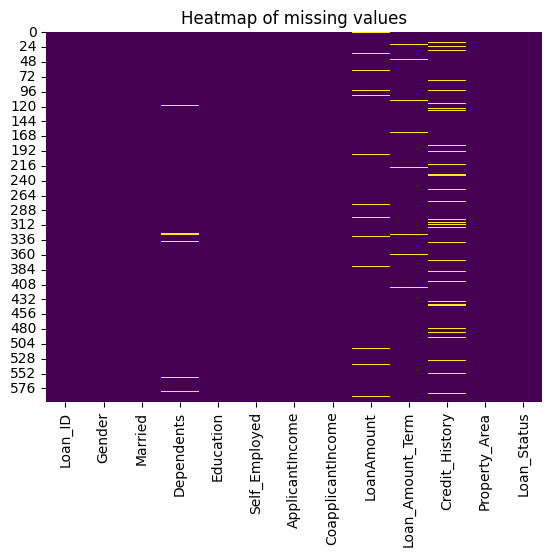

In [179]:
sns.heatmap(df.isnull(), cbar= False, cmap= 'viridis')
plt.title('Heatmap of missing values')
plt.show()

The heatmap was used to visualize missing values in the dataset. The plot clearly highlights some columns containing null values, making it easier to identify features that require data cleaning or imputation before model training. 


### checking null values

In [180]:
df.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents           12
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           21
Loan_Amount_Term     14
Credit_History       49
Property_Area         0
Loan_Status           0
dtype: int64

The dataset contains missing values in both numerical and classification-type features. Dependents has 12 missing values, LoanAmount has 21, Loan_Amount_Term has 14, and Credit_History has 49 missing values. While Dependents, LoanAmount, and Loan_Amount_Term are numerical features, Credit_History represents a binary classification variable (0 or 1).

## Null Value Handling

### Distribution of Numerical features

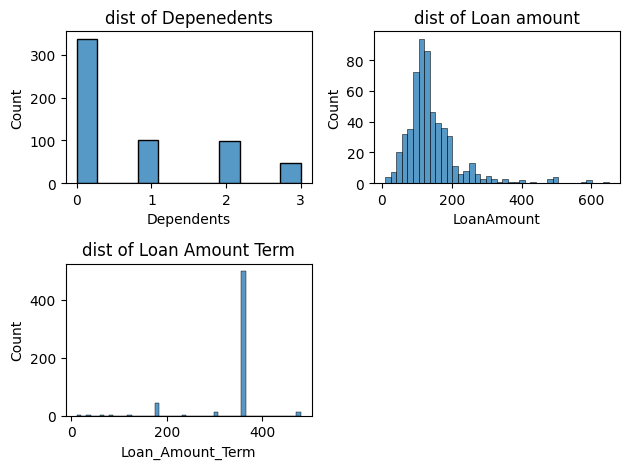

In [181]:
plt.subplot(2,2,1)
sns.histplot(df['Dependents'])
plt.title("dist of Depenedents")

plt.subplot(2,2,2)
sns.histplot(df['LoanAmount'])
plt.title("dist of Loan amount")

plt.subplot(2,2,3)
sns.histplot(df['Loan_Amount_Term'])
plt.title("dist of Loan Amount Term")


plt.tight_layout()
plt.show()

Histograms were plotted for numerical features with missing values to understand their distributions. LoanAmount is right-skewed with some outliers, while Loan_Amount_Term and Dependents are concentrated around specific values. Therefore, median imputation was chosen to handle the missing values.

In [182]:
num = ['Dependents','LoanAmount','Loan_Amount_Term']
for col in num:
    df[col] = df[col].fillna(df[col].median())

Missing values in numerical columns are filled using the median, based on the histogram distribution, to handle skewed data and outliers.

In [183]:
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

The Credit_History feature was analyzed separately because it is a binary classification variable (0 or 1). Most applicants have a value of 1, making it the most frequent class. Therefore, mode imputation was used to fill the missing values.

### Final Verify - Missing Values

In [184]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

There is no missing values, handled properly.

### Check Duplicates

In [185]:
df.duplicated().sum()

np.int64(0)

No duplicate records were found in the dataset.

### Checking Data Types

In [186]:
df.dtypes

Loan_ID                  str
Gender                   str
Married                  str
Dependents           float64
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

### Data Type Summary

The dataset contains a mix of categorical and numerical features. Categorical variables such as Gender, Married, Education, Self_Employed, Property_Area, and Loan_Status are stored as string (object) data types. Numerical variables, including ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Dependents, and Credit_History, are stored as integer or float data types. The Loan_ID feature serves as a unique identifier for each loan application and does not contribute to the prediction process.

### Removing Unwanted Features

In [187]:
df = df.drop(columns=['Loan_ID'])

The Loan_ID column was removed because it is only a unique identifier and does not help in predicting loan approval.

## Univariate Analysis

### Histogram

In [188]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

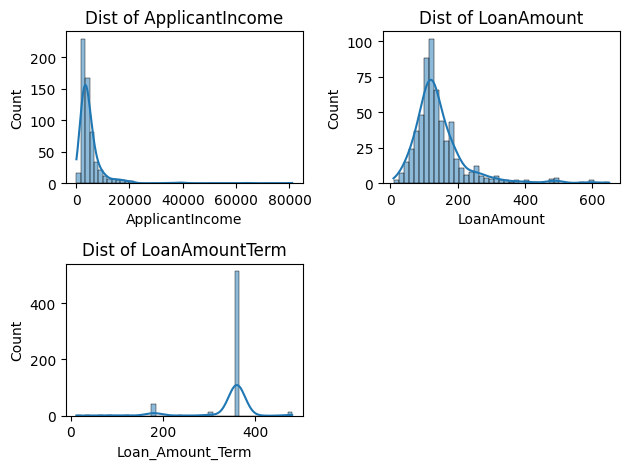

In [189]:
plt.subplot(2,2,1)
sns.histplot(df['ApplicantIncome'], kde=True)
plt.title('Dist of ApplicantIncome')

plt.subplot(2,2,2)
sns.histplot(df['LoanAmount'], kde=True)
plt.title('Dist of LoanAmount')

plt.subplot(2,2,3)
sns.histplot(df['Loan_Amount_Term'], kde=True)
plt.title('Dist of LoanAmountTerm')

plt.tight_layout()
plt.show()

Insight

The Histogram shows that the ApplicantIncome and LoanAmount features show a slightly right-skewed distribution, indicating that a few applicants have higher income and loan amounts than the majority. The Loan_Amount_Term feature is highly concentrated at 360 months, showing that most applicants prefer a 30-year repayment period.


## Boxplot for Outliers

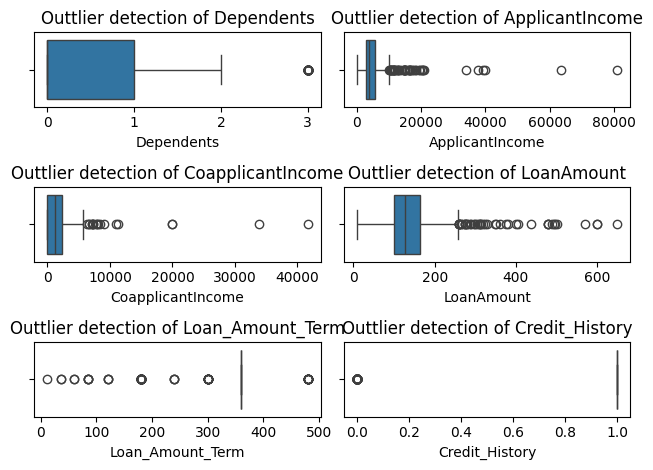

In [190]:
plt.subplot(3,2,1)
sns.boxplot(data=df, x='Dependents')
plt.title('Outtlier detection of Dependents')

plt.subplot(3,2,2)
sns.boxplot(data=df, x='ApplicantIncome')
plt.title('Outtlier detection of ApplicantIncome')

plt.subplot(3,2,3)
sns.boxplot(data=df, x='CoapplicantIncome')
plt.title('Outtlier detection of CoapplicantIncome')

plt.subplot(3,2,4)
sns.boxplot(data=df, x='LoanAmount')
plt.title('Outtlier detection of LoanAmount')

plt.subplot(3,2,5)
sns.boxplot(data=df, x='Loan_Amount_Term')
plt.title('Outtlier detection of Loan_Amount_Term')

plt.subplot(3,2,6)
sns.boxplot(data=df, x='Credit_History')
plt.title('Outtlier detection of Credit_History')


plt.tight_layout()
plt.show()

### Outlier Analysis

The boxplots reveal outliers in ApplicantIncome, CoapplicantIncome, and LoanAmount. These outliers represent a small number of applicants with unusually high values, while the remaining features show minimal or no significant outlier issues.


### Outlier Treatment

In [191]:
def Cap(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_boundary =Q1 - 1.5 * IQR

    upper_bounday = Q3 + 1.5 * IQR

    return df[col].clip(lower = lower_boundary, upper = upper_bounday)

print(df.select_dtypes(include=['number']).columns)

numerics = ['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History']

for col in numerics:
    df[col] = Cap(df, col)

Index(['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='str')


Instead of removing outliers, capping was applied using the IQR method. This approach limits extreme values to the upper and lower boundaries while retaining all observations in the dataset. Capping helps reduce the impact of outliers without losing valuable information.


### Recheck Outlier Using Boxplot

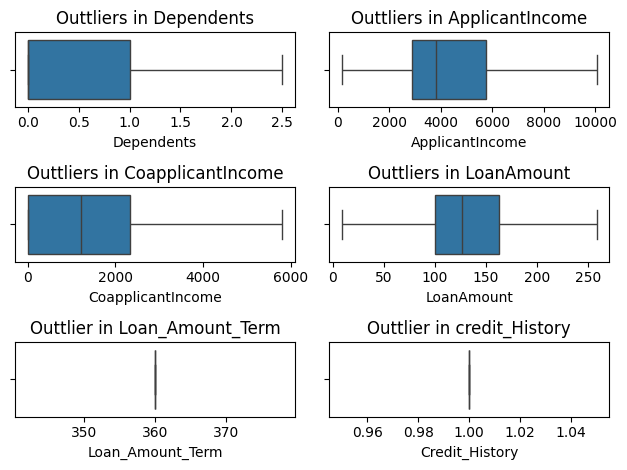

In [192]:
plt.subplot(3,2,1)
sns.boxplot(data=df, x='Dependents')
plt.title('Outtliers in Dependents')

plt.subplot(3,2,2)
sns.boxplot(data=df, x='ApplicantIncome')
plt.title('Outtliers in ApplicantIncome')

plt.subplot(3,2,3)
sns.boxplot(data=df, x='CoapplicantIncome')
plt.title('Outtliers in CoapplicantIncome')

plt.subplot(3,2,4)
sns.boxplot(data=df, x='LoanAmount')
plt.title('Outtliers in LoanAmount')

plt.subplot(3,2,5)
sns.boxplot(data=df, x='Loan_Amount_Term')
plt.title('Outtlier in Loan_Amount_Term')

plt.subplot(3,2,6)
sns.boxplot(data=df, x='Credit_History')
plt.title('Outtlier in credit_History')


plt.tight_layout()
plt.show()

Insight


No significant outliers are visible after capping, indicating that the outlier treatment was effective.

## Correlation Heatmap & Analysis

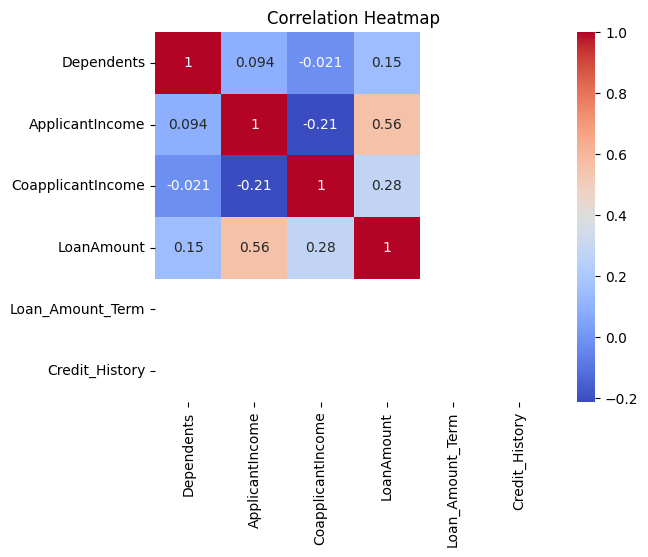

In [193]:
plt.Figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot= True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

The correlation heatmap shows the relationships between the numerical features in the dataset: Dependents, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, and Credit_History. Most features show very weak correlation with each other, with values close to 0, meaning they don't have a strong linear relationship. The strongest correlation observed is between ApplicantIncome and LoanAmount (0.52), which makes sense since applicants with higher income tend to apply for or qualify for higher loan amounts. Apart from this, no other pair of features shows a notable correlation, and most values lie between -0.11 and 0.21, indicating that multicollinearity is not a major concern in this dataset. Overall, the features appear to be fairly independent of each other.

## Bivariate Analysis

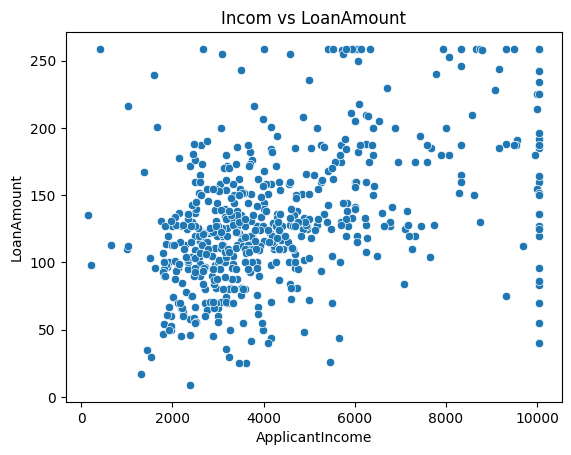

In [194]:
sns.scatterplot(data= df, x='ApplicantIncome', y='LoanAmount')
plt.title('Incom vs LoanAmount')
plt.show()

Insight

 Higher-income applicants generally apply for larger loans, but the relationship is moderate rather than very strong.

### Categorical Analysis

<Axes: xlabel='Self_Employed', ylabel='count'>

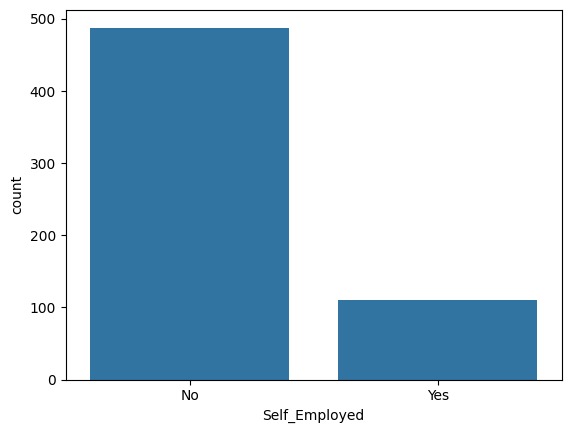

In [195]:
sns.countplot(data=df, x='Self_Employed')

Insight

The majority of applicants are not self-employed, while only a smaller portion of applicants are self-employed. This indicates that most loan applications in the dataset come from salaried individuals.

### Check Value count of Target

In [196]:
df['Loan_Status'].value_counts()

Loan_Status
Y    411
N    187
Name: count, dtype: int64

### Class Distribution Analysis

The target variable is imbalanced, containing **411 approved loans** and **187 rejected loans**. To balance the class distribution and reduce prediction bias,need to perform **Random Oversampling** before model training.


### Feature and Target Separation

In [197]:
x = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']


The dataset was divided into independent features (X) and the target variable (y). The Loan_Status column was selected as the target variable, while all remaining columns were used as input features for model training. This separation was performed before applying oversampling, encoding, and scaling techniques.

## Random Over Sampling

In [198]:
from imblearn.over_sampling import RandomOverSampler
roc = RandomOverSampler(random_state= 42)

x, y = roc.fit_resample(x, y)
y.value_counts()

Loan_Status
Y    411
N    411
Name: count, dtype: int64

Random Oversampling was applied to balance the target classes. The minority class was increased to match the majority class, reducing model bias and improving learning from both loan approval outcomes.

## Encoding

In [199]:
categorical = x.select_dtypes(include='object')
print(categorical.nunique())

Gender           2
Married          2
Education        2
Self_Employed    2
Property_Area    3
dtype: int64


C:\Users\shamn\AppData\Local\Temp\ipykernel_28888\541900624.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = x.select_dtypes(include='object')


The categorical features in the dataset were identified and analyzed by examining the number of unique categories in each column. Most features contain two categories, making them suitable for Label Encoding

### Label Encoding

In [200]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in categorical:           # using forloop. Label encoder expect 1D
    x[col] = le.fit_transform(x[col])

y = le.fit_transform(y)

x.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,1,0,0.0,0,0,5849.0,0.0,127.0,360.0,1.0,2
1,1,1,1.0,0,0,4583.0,1508.0,128.0,360.0,1.0,0
2,1,1,0.0,0,1,3000.0,0.0,66.0,360.0,1.0,2
3,1,1,0.0,1,0,2583.0,2358.0,120.0,360.0,1.0,2
4,1,0,0.0,0,0,6000.0,0.0,141.0,360.0,1.0,2


Categorical features were converted into numerical values using Label Encoding. Since LabelEncoder works with one-dimensional (1D) data, a loop was used to encode each categorical column individually. This transformation makes the data suitable for machine learning algorithms while preserving the information in each category.

## Scaling

### Use StandardScaler

In [201]:
numeric = ['ApplicantIncome','CoapplicantIncome', 'LoanAmount','Loan_Amount_Term']

from sklearn.preprocessing import StandardScaler
stanrdaize = StandardScaler()
x[numeric] = stanrdaize.fit_transform(x[numeric]) # Standardscaler expect 2D




Numerical features were standardized using StandardScaler. Since StandardScaler expects two-dimensional (2D) input data, the selected numerical columns were passed as a DataFrame. This process transforms the features to have a mean of 0 and a standard deviation of 1, ensuring that all numerical variables are on a similar scale.

## Train Test Split

In [202]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state= 42)

for training 80% 
for testing 20%

# MODEL TRAINING AND PREDICTING

### LogisticRegression

In [203]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)

### KNN

In [204]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors= 4)
knn.fit(x_train, y_train)
knn_pred = knn.predict(x_test)



### RandomForestClassifier

In [205]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators= 100, max_depth= 3, random_state= 42)
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)




### Naive Bayes

In [206]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(x_train, y_train)
nb_pred = nb.predict(x_test)


### XGB

In [207]:
from xgboost import XGBClassifier
xgb = XGBClassifier(learning_rate = 0.1, n_estimators = 100)
xgb.fit(x_train, y_train)
xgb_pred = xgb.predict(x_test)


### Summary

Multiple classification models, including Logistic Regression, K-Nearest Neighbors (KNN), Random Forest, Naive Bayes, and XGBoost, were trained on the preprocessed dataset. Predictions were generated on the test set and prepared for further performance evaluation and model comparison.


# MODEL EVALUATION

### ACCURACY

In [208]:
from sklearn.metrics import accuracy_score
print(f'accuracy score of Logistic Regression: {accuracy_score(y_test, lr_pred)}')
print(f'accuracy score of KNN: {accuracy_score(y_test, knn_pred)}')
print(f'accuracy score of Random Forest: {accuracy_score(y_test, rf_pred)}')
print(f'accuracy score of Naive Bayes: {accuracy_score(y_test, nb_pred)}')
print(f'accuracy score of XGB: {accuracy_score(y_test, xgb_pred)}')


accuracy score of Logistic Regression: 0.5393939393939394
accuracy score of KNN: 0.6727272727272727
accuracy score of Random Forest: 0.6121212121212121
accuracy score of Naive Bayes: 0.49696969696969695
accuracy score of XGB: 0.7818181818181819


XGBoost achieved the highest accuracy of 78%, indicating the best overall classification performance among the evaluated models.

### PRESICION

In [209]:
from sklearn.metrics import precision_score

print(f'Precision score of Logistic Regression: {precision_score(y_test, lr_pred)}')
print(f'Precision score of KNN: {precision_score(y_test, knn_pred)}')
print(f'Precision score of rf: {precision_score(y_test, rf_pred)}')
print(f'Precision score of nb: {precision_score(y_test, nb_pred)}')
print(f'Precision score of xgb: {precision_score(y_test, xgb_pred)}')

Precision score of Logistic Regression: 0.5421686746987951
Precision score of KNN: 0.7735849056603774
Precision score of rf: 0.6266666666666667
Precision score of nb: 0.5
Precision score of xgb: 0.821917808219178


XGBoost achieved the highest precision of 82 %, showing that its positive predictions were more reliable than those of the other models.

### RECALL

In [210]:
from sklearn.metrics import recall_score

print(f'recall score of lr: {recall_score(y_test, lr_pred)}')
print(f'recall score of knn: {recall_score(y_test, knn_pred)}')
print(f'recall score of rf: {recall_score(y_test, rf_pred)}')
print(f'recall score of nb: {recall_score(y_test, nb_pred)}')
print(f'recall score of xgb: {recall_score(y_test, xgb_pred)}')

recall score of lr: 0.5421686746987951
recall score of knn: 0.4939759036144578
recall score of rf: 0.5662650602409639
recall score of nb: 0.5903614457831325
recall score of xgb: 0.7228915662650602


xgb achieved the highest recall of 72%

### F1 SCORE

In [211]:
from sklearn.metrics import f1_score
print(f'f1 score of lr: {f1_score(y_test, lr_pred)}')
print(f'f1 score of knn: {f1_score(y_test, knn_pred)}')
print(f'f1 score of rf: {f1_score(y_test, rf_pred)}')
print(f'f1 score of nb: {f1_score(y_test, nb_pred)}')
print(f'f1 score of xgb: {f1_score(y_test, xgb_pred)}')

f1 score of lr: 0.5421686746987951
f1 score of knn: 0.6029411764705882
f1 score of rf: 0.5949367088607594
f1 score of nb: 0.5414364640883977
f1 score of xgb: 0.7692307692307693


xgb achieved the highest F1-score of 79.93%, indicating the best balance between precision and recall.

## Model Selection

The performance of all classification models was compared using Accuracy, Precision, Recall, and F1-Score. Among the evaluated models, **XGBoost achieved the highest performance across all evaluation metrics**, demonstrating the best overall ability to classify loan approval outcomes. Therefore, XGBoost was selected as the final model for hyperparameter tuning and further evaluation.



## Cross Validation

In [212]:
from sklearn.model_selection import GridSearchCV
parms = {'learning_rate':[0.1, 0.3, 0.5], 'n_estimators':[50,100,200]}
grid = GridSearchCV(xgb, parms, cv=5)
grid.fit(x_train, y_train)
grid.best_params_

{'learning_rate': 0.1, 'n_estimators': 200}

### Hyperparameter Tuning

GridSearchCV was applied to the XGBoost model using 5-fold cross-validation. The optimal parameters obtained were `learning_rate = 0.1` and `n_estimators = 200`, which were used to improve model performance and achieve better classification results.


### Final Model Training

In [213]:
final_model = XGBClassifier(learning_rate= 0.1, n_estimators= 200)
final_model.fit(x_train, y_train)
final_pred = final_model.predict(x_test)
accuracy_score(y_test, final_pred)

0.8121212121212121


The XGBoost model was retrained using the optimal hyperparameters obtained from GridSearchCV (`learning_rate = 0.1` and `n_estimators = 200`). After training, predictions were generated on the test set, and the model achieved an accuracy of **81%**. This improvement demonstrates that the tuned model performs effectively in predicting loan approval outcomes and provides better overall classification performance.


### Confusion Matrix

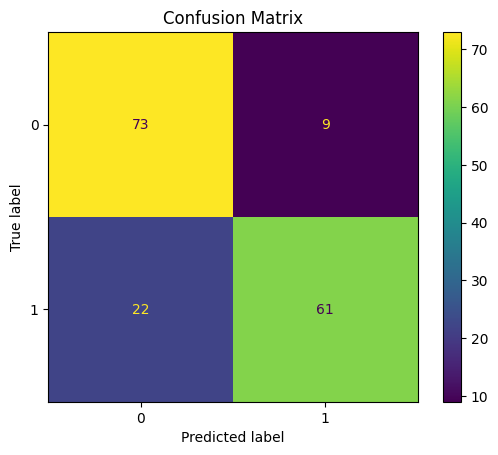

In [214]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, final_pred)
ConfusionMatrixDisplay(cm).plot()
plt.title('Confusion Matrix')
plt.show()



Insight   



The model correctly predicted 70 out of 82 class 0 cases and 60 out of 83 class 1 cases. Only 12 class 0 cases were wrongly predicted as class 1, and 23 class 1 cases were wrongly predicted as class 0. Overall the model is performing well and is fairly balanced in predicting both classes. It is not biased toward any one class, which means the predictions are reliable. The model has a good understanding of the data and can identify both loan approved and loan rejected cases with reasonable accuracy.

### ROC Curve and AUC Score

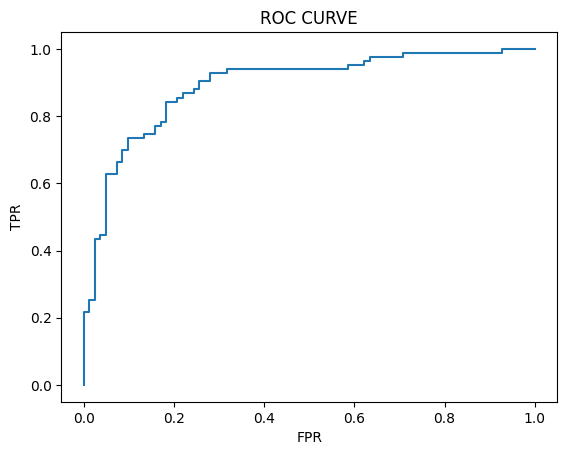

AUC Score: 0.8914193358801058


In [215]:
from sklearn.metrics import roc_curve, roc_auc_score
y_score = final_model.predict_proba(x_test)[:,1]

fpr, tpr, threshold = roc_curve(y_test, y_score)
plt.plot(fpr, tpr)
plt.title("ROC CURVE")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()

print("AUC Score:", roc_auc_score(y_test, y_score))

### ROC Curve and AUC Score

The ROC Curve was plotted to evaluate the performance of the final XGBoost model. The model achieved an AUC score of **0.89**, indicating an excellent ability to distinguish between approved and rejected loan applications. This significant improvement demonstrates that the model can effectively separate the two classes and provides strong predictive performance.



## Conclusion

In this project, a loan approval prediction model was developed using machine learning techniques. The dataset was preprocessed by handling missing values, treating outliers, balancing the target classes through Random Oversampling, encoding categorical features, and scaling numerical features. Multiple classification algorithms, including Logistic Regression, KNN, Random Forest, Naive Bayes, and XGBoost, were trained and evaluated using various performance metrics. Among all the models, XGBoost achieved the best overall performance and was selected as the final model. After hyperparameter tuning with GridSearchCV, the final model achieved an accuracy of **81%** and an AUC score of **0.89**. These results indicate that the model can effectively distinguish between approved and rejected loan applications and can be used as a reliable tool for supporting loan approval decisions.

